# Manufacturing Analytics — Case Study
## From Machine Data to Money: Manufacturing Intelligence at a CNC Components Plant

> **Illustrative case study on synthetic data.** *Shree Precision Components* is a fictional auto-component maker.
> All data below is simulated (seeded, reproducible) to show the method and the kind of output Arihant Analytics delivers.
> The figures are **not** results from a real client.

**The plant:** 15 CNC machines · 3 lines · 3 shifts/day · 180 operating days.

**The problem (from our pitch deck):** manual Excel reports, reactive maintenance, late-caught defects, and no live view of OEE.
Unplanned downtime is valued at **₹3 Lakh/hour** (midpoint of the ₹2–5 Lakh range quoted in the deck).

**What this notebook covers**

| # | Deck service | Question answered |
|---|---|---|
| 1 | Real-Time Production Dashboard | What is our OEE and where is it leaking? |
| 2 | Predictive Maintenance | Can sensors warn us 3–7 days before a breakdown? |
| 3 | Quality Control & SPC | Which machines/shifts produce scrap, and can SPC catch drift early? |
| 4 | Business Impact | What is all of this worth in ₹? |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, confusion_matrix

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, GREY, RED = "#2a6fdb", "#e07b00", "#8a8f98", "#c43d3d"

RNG = np.random.default_rng(42)
N_MACH, N_DAYS = 15, 180
HOURS = N_DAYS * 24
COST_PER_DOWN_HR = 3_00_000          # Rs, from deck (2-5 Lakh/hr midpoint)
SCRAP_COST_PER_PART = 180            # Rs, assumed material + machining value
WORKING_DAYS_PER_YEAR = 300          # to annualise the 180-day sample
ANNUAL = WORKING_DAYS_PER_YEAR / N_DAYS
machines = [f"M{i:02d}" for i in range(1, N_MACH + 1)]
line_of = {m: f"Line {1 + i // 5}" for i, m in enumerate(machines)}

## 1. Build the data (what an MES / SCADA / IoT feed would give us)

Three sources, joined on machine and time:
* **Sensor stream** — hourly vibration, temperature, pressure per machine (IoT / SCADA)
* **Shift production log** — planned time, downtime by reason, counts (MES)
* **QC measurements** — sub-grouped bore diameters from the CMM / gauge (QC system)

Breakdowns are injected first. Before each one, the sensors degrade gradually over 3–7 days — that is the signal the ML model must find.

In [2]:
# ---- 1a. Failure events + hourly sensor stream -------------------------------------------
sensor_rows, failures = [], []
for m in machines:
    t = int(RNG.integers(24*10, 24*30))
    fail_hours = []
    while t < HOURS - 24*3:
        fail_hours.append(t)
        t += int(RNG.integers(24*35, 24*80))          # next failure 5-11 weeks later
    base_v, base_t, base_p = RNG.normal(2.0, .15), RNG.normal(62, 2), RNG.normal(6.0, .1)
    v = base_v + RNG.normal(0, .18, HOURS)
    temp = base_t + RNG.normal(0, 1.2, HOURS) + 2*np.sin(np.arange(HOURS)*2*np.pi/24)   # daily cycle
    p = base_p + RNG.normal(0, .08, HOURS)
    down = np.zeros(HOURS, bool)
    for fh in fail_hours:
        lead = int(RNG.integers(3, 8)) * 24              # degradation starts 3-7 days before
        ramp = np.linspace(0, 1, lead) ** 1.5
        s = max(0, fh - lead)
        n = fh - s
        v[s:fh] += ramp[-n:] * RNG.uniform(1.6, 2.6)
        temp[s:fh] += ramp[-n:] * RNG.uniform(8, 14)
        p[s:fh] -= ramp[-n:] * RNG.uniform(.4, .8)
        rep = int(RNG.integers(6, 21))                   # repair takes 6-20 h
        down[fh:fh+rep] = True
        failures.append((m, fh, rep))
    df = pd.DataFrame({"machine": m, "hour": np.arange(HOURS), "vibration": v, "temp": temp,
                       "pressure": p, "down": down})
    sensor_rows.append(df)
sensors = pd.concat(sensor_rows, ignore_index=True)
failures = pd.DataFrame(failures, columns=["machine", "fail_hour", "repair_hrs"])
print(f"{len(failures)} breakdowns in {N_DAYS} days | avg repair {failures.repair_hrs.mean():.1f} h")
sensors.head(3)

49 breakdowns in 180 days | avg repair 13.5 h


,machine,hour,vibration,temp,pressure,down
0,M01,0,1.88,63.35,5.78,False
1,M01,1,2.14,65.65,5.79,False
2,M01,2,2.06,65.45,5.85,False


In [3]:
# ---- 1b. Shift production log (MES) --------------------------------------------------------
bad_machines = {"M04": 2.6, "M11": 2.2}                  # two machines with a quality problem
shift_effect_perf = {0: 0.0, 1: -0.02, 2: -0.06}         # night shift performs worse
shift_effect_def  = {0: 0.0, 1: 0.004, 2: 0.012}
reasons = ["Changeover", "Tool change", "Material wait", "Minor stops"]
rows = []
for m in machines:
    ict = RNG.uniform(30, 55)                            # ideal cycle time, seconds
    hrs_down = sensors.loc[sensors.machine == m, "down"].to_numpy()
    for d in range(N_DAYS):
        for sh in range(3):
            h0 = d*24 + sh*8
            planned = 450                                # 480 min shift - 30 min break
            bd = hrs_down[h0:h0+8].sum() * 60
            bd = min(bd, planned)
            other = {r: float(max(0, RNG.normal(mu, sd))) for r, mu, sd in
                     [("Changeover", 18, 8), ("Tool change", 12, 5), ("Material wait", 8, 6), ("Minor stops", 14, 6)]}
            tot_other = sum(other.values())
            if bd + tot_other > planned:
                f = (planned - bd) / tot_other if tot_other else 0
                other = {k: x*f for k, x in other.items()}
            run = planned - bd - sum(other.values())
            perf = np.clip(RNG.normal(.90 + shift_effect_perf[sh], .04), .6, 1.0)
            total = int(run*60/ict*perf)
            dr = np.clip(RNG.normal(.022 + shift_effect_def[sh], .006), .002, .2) * bad_machines.get(m, 1)
            bad = int(RNG.binomial(total, min(dr, .5))) if total else 0
            rows.append(dict(day=d, shift=sh+1, machine=m, line=line_of[m], planned_min=planned,
                             breakdown_min=bd, **{r: other[r] for r in reasons},
                             ideal_ct_s=ict, total=total, good=total-bad))
prod = pd.DataFrame(rows)
prod["downtime_min"] = prod[["breakdown_min"] + reasons].sum(axis=1)
prod["run_min"] = prod.planned_min - prod.downtime_min
prod["A"] = prod.run_min / prod.planned_min
prod["P"] = (prod.total * prod.ideal_ct_s / 60) / prod.run_min.replace(0, np.nan)
prod["Q"] = prod.good / prod.total.replace(0, np.nan)
prod["OEE"] = prod.A * prod.P * prod.Q
prod.head(3)

,day,shift,machine,line,planned_min,breakdown_min,Changeover,Tool change,Material wait,Minor stops,ideal_ct_s,total,good,downtime_min,run_min,A,P,Q,OEE
0,0,1,M01,Line 1,450,0,14.83,22.24,22.18,16.14,38.27,530,523,75.39,374.61,0.83,0.90,0.99,0.74
1,0,2,M01,Line 1,450,0,25.33,16.66,15.88,9.37,38.27,526,513,67.24,382.76,0.85,0.88,0.98,0.73
2,0,3,M01,Line 1,450,0,11.75,16.67,2.18,5.66,38.27,523,504,36.26,413.74,0.92,0.81,0.96,0.71


## 2. Real-Time Production Dashboard — *where is OEE leaking?*

**OEE = Availability × Performance × Quality.** World-class is ~85%; most Indian job-shop/auto-component plants sit well below that.
We aggregate properly (sum of times and counts), not by averaging ratios, which would be wrong.

PLANT OEE  Availability: 87.4%  |  Performance: 87.3%  |  Quality: 96.7%  |  OEE: 73.8%


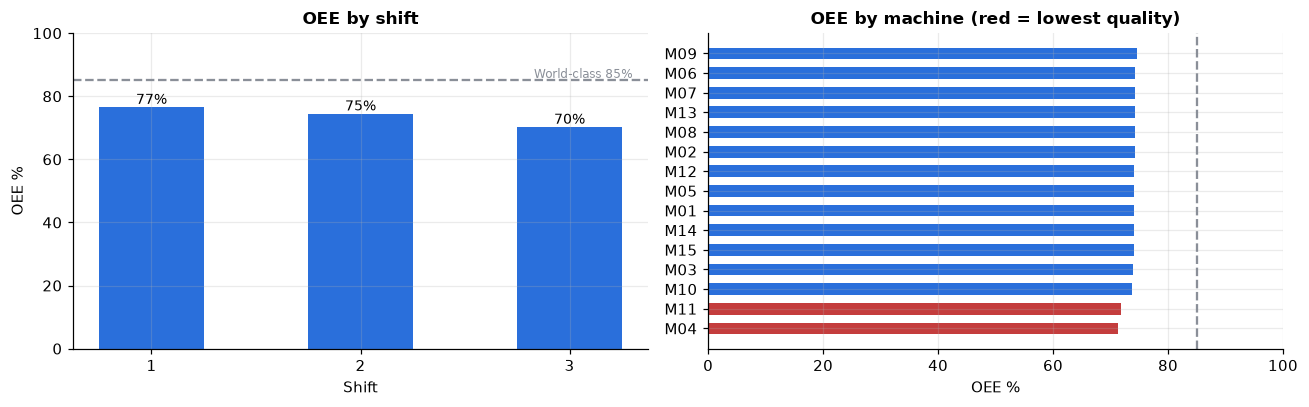

,Availability,Performance,Quality,OEE
machine,,,,
M04,0.88,0.88,0.93,0.71
M11,0.88,0.87,0.94,0.72
M10,0.87,0.87,0.97,0.74
M03,0.87,0.87,0.97,0.74
M15,0.87,0.87,0.97,0.74


In [4]:
def oee(g):
    run, planned = g.run_min.sum(), g.planned_min.sum()
    A = run / planned
    P = (g.total * g.ideal_ct_s / 60).sum() / run
    Q = g.good.sum() / g.total.sum()
    return pd.Series({"Availability": A, "Performance": P, "Quality": Q, "OEE": A*P*Q})

plant = oee(prod)
print("PLANT OEE  " + "  |  ".join(f"{k}: {v:.1%}" for k, v in plant.items()))

by_shift = prod.groupby("shift").apply(oee, include_groups=False)
by_mach = prod.groupby("machine").apply(oee, include_groups=False).sort_values("OEE")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(by_shift.index.astype(str), by_shift.OEE*100, color=BLUE, width=.5)
ax[0].axhline(85, color=GREY, ls="--"); ax[0].text(2.3, 85.8, "World-class 85%", ha="right", color=GREY, fontsize=8)
for i, v in enumerate(by_shift.OEE*100): ax[0].text(i, v+1, f"{v:.0f}%", ha="center", fontsize=9)
ax[0].set(title="OEE by shift", xlabel="Shift", ylabel="OEE %", ylim=(0, 100))
colors = [RED if m in bad_machines else BLUE for m in by_mach.index]
ax[1].barh(by_mach.index, by_mach.OEE*100, color=colors, height=.6)
ax[1].axvline(85, color=GREY, ls="--"); ax[1].set(title="OEE by machine (red = lowest quality)", xlabel="OEE %", xlim=(0, 100))
plt.tight_layout(); plt.show()
by_mach.round(3).head(5)

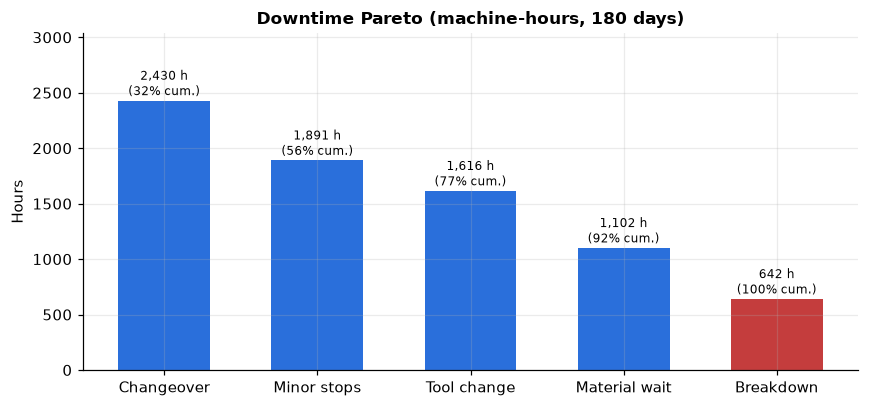

Unplanned breakdown: 642 machine-hours = Rs 19.2 Cr over 180 days


In [5]:
# Downtime Pareto - the 'what do we fix first' chart
dt = prod[["breakdown_min"] + reasons].sum().rename({"breakdown_min": "Breakdown"}).sort_values(ascending=False) / 60
cum = dt.cumsum() / dt.sum() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dt.index, dt.values, color=[RED if i == "Breakdown" else BLUE for i in dt.index], width=.6)
ax.set(title="Downtime Pareto (machine-hours, 180 days)", ylabel="Hours")
for i, (v, c) in enumerate(zip(dt.values, cum.values)):
    ax.text(i, v + dt.max()*.02, f"{v:,.0f} h\n({c:.0f}% cum.)", ha="center", fontsize=8)
ax.set_ylim(0, dt.max()*1.25); plt.tight_layout(); plt.show()

bd_hours = prod.breakdown_min.sum()/60
print(f"Unplanned breakdown: {bd_hours:,.0f} machine-hours = Rs {bd_hours*COST_PER_DOWN_HR/1e7:,.1f} Cr over 180 days")

**Reading it:** Availability and Performance cost us more than Quality, and the night shift is visibly weaker.
Breakdown hours are the rarest but most expensive category. That is the lever Section 3 pulls.

## 3. Predictive Maintenance — *warn us before it breaks*

Goal: predict **"this machine fails within the next 7 days"** from sensor behaviour.

Design choices that matter (and that we would explain to a client):
* **Rolling features** (24h mean/std, change vs. the machine's own 14-day baseline) — a machine's *drift*, not its absolute level, is the signal.
* **Time-based split** — train on the first 120 days, test on the last 60. A random split would leak the future and overstate accuracy.
* **Random Forest** with class balancing, since failure windows are a minority class.
* Rows during repair are removed.

In [6]:
sensors = sensors.sort_values(["machine", "hour"]).reset_index(drop=True)
g = sensors.groupby("machine")
feat = []
for col in ["vibration", "temp", "pressure"]:
    r24 = g[col].rolling(24, min_periods=12)
    sensors[f"{col}_24h_mean"] = r24.mean().reset_index(level=0, drop=True)
    sensors[f"{col}_24h_std"]  = r24.std().reset_index(level=0, drop=True)
    base = g[col].rolling(24*14, min_periods=24*3).mean().shift(24*2).reset_index(level=0, drop=True)  # lagged baseline
    sensors[f"{col}_drift"] = sensors[f"{col}_24h_mean"] - base
    feat += [f"{col}_24h_mean", f"{col}_24h_std", f"{col}_drift"]

# label: failure in next 7 days
sensors["y"] = 0
for m, fh, rep in failures.itertuples(index=False):
    mask = (sensors.machine == m) & (sensors.hour >= fh - 24*7) & (sensors.hour < fh)
    sensors.loc[mask, "y"] = 1
data = sensors.loc[~sensors.down].dropna(subset=feat).copy()
SPLIT = 120 * 24
train, test = data[data.hour < SPLIT], data[data.hour >= SPLIT]
print(f"train rows {len(train):,} (pos {train.y.mean():.1%}) | test rows {len(test):,} (pos {test.y.mean():.1%})")

clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=0)
clf.fit(train[feat], train.y)
test = test.assign(p=clf.predict_proba(test[feat])[:, 1])
THRESH = 0.5
pred = (test.p >= THRESH).astype(int)
print(f"ROC-AUC {roc_auc_score(test.y, test.p):.3f} | precision {precision_score(test.y, pred):.2f} | recall {recall_score(test.y, pred):.2f}")
print(pd.DataFrame(confusion_matrix(test.y, pred), index=["actual OK", "actual pre-fail"], columns=["pred OK", "pred pre-fail"]))

train rows 41,504 (pos 13.4%) | test rows 21,368 (pos 12.5%)


ROC-AUC 0.843 | precision 0.73 | recall 0.57
                 pred OK  pred pre-fail
actual OK          18127            569
actual pre-fail     1158           1514


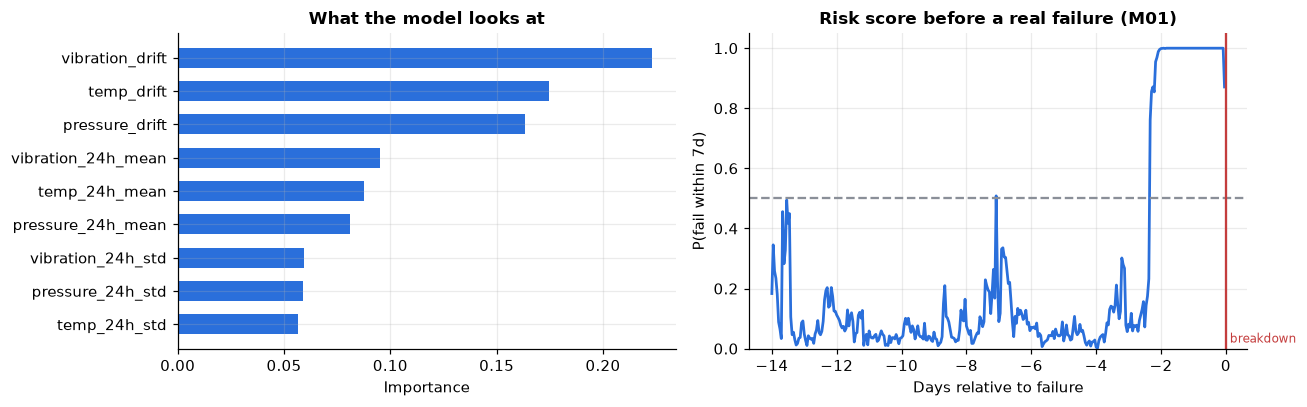

In [7]:
imp = pd.Series(clf.feature_importances_, feat).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(imp.index, imp.values, color=BLUE, height=.6); ax[0].set(title="What the model looks at", xlabel="Importance")

# one failing machine in the test window: risk score over time
ev = failures[failures.fail_hour >= SPLIT].iloc[0]
w = test[(test.machine == ev.machine) & (test.hour.between(ev.fail_hour - 24*14, ev.fail_hour))]
ax[1].plot((w.hour - ev.fail_hour)/24, w.p, color=BLUE, lw=1.8)
ax[1].axhline(THRESH, color=GREY, ls="--"); ax[1].axvline(0, color=RED)
ax[1].text(0, .02, " breakdown", color=RED, fontsize=8)
ax[1].set(title=f"Risk score before a real failure ({ev.machine})", xlabel="Days relative to failure", ylabel="P(fail within 7d)", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

### Does the model give *useful lead time*, event by event?
Row-level accuracy is not what a maintenance planner cares about. They care: **for each real breakdown, did we raise an alert early enough to schedule a planned stop?**
We require an alert (score ≥ threshold for 3 consecutive hours, to avoid noise) at least **24 h** before the failure, and count false alarms as alert episodes with no failure within 7 days.

In [8]:
MIN_LEAD_H, PLANNED_STOP_H = 24, 2        # planned intervention takes ~2 h instead of an unplanned repair
test = test.sort_values(["machine", "hour"])
test["hot"] = (test.groupby("machine").p.transform(lambda s: (s >= THRESH).rolling(3).min()).fillna(0) == 1)

ev_test = failures[failures.fail_hour >= SPLIT].copy()
leads = []
for m, fh, rep in ev_test.itertuples(index=False):
    h = test[(test.machine == m) & test.hot & (test.hour < fh) & (test.hour >= fh - 24*7)]
    leads.append((fh - h.hour.min())/24 if len(h) else np.nan)
ev_test["lead_days"] = leads
ev_test["caught"] = ev_test.lead_days * 24 >= MIN_LEAD_H

# false-alarm episodes: first 'hot' hour of a run with no failure in the next 7 days
fa = 0
for m, d in test.groupby("machine"):
    hot_h = d.loc[d.hot, "hour"].to_numpy()
    if not len(hot_h): continue
    starts = hot_h[np.r_[True, np.diff(hot_h) > 24]]
    fh_m = failures.loc[failures.machine == m, "fail_hour"].to_numpy()
    fa += sum(not ((fh_m >= s) & (fh_m - s <= 24*7)).any() for s in starts)

print(ev_test[["machine", "repair_hrs", "lead_days", "caught"]].round(1).to_string(index=False))
print(f"\nBreakdowns caught with >= {MIN_LEAD_H}h notice: {ev_test.caught.sum()} of {len(ev_test)}"
      f" | median lead {ev_test.lead_days.median():.1f} days | false-alarm episodes: {fa}")

machine  repair_hrs  lead_days  caught
    M01           6       2.20    True
    M02          14       2.20    True
    M03           7       3.90    True
    M04          15       4.00    True
    M05           7       5.10    True
    M05          20       6.80    True
    M06           9       0.50   False
    M07          18       7.00    True
    M08          15       4.80    True
    M09          14       2.20    True
    M10          15       5.60    True
    M10           8       4.00    True
    M11          10       5.90    True
    M12          19       2.40    True
    M12          16       2.80    True
    M13          16       4.90    True
    M14          14       6.00    True

Breakdowns caught with >= 24h notice: 16 of 17 | median lead 4.0 days | false-alarm episodes: 45


In [9]:
caught = ev_test[ev_test.caught]
ACT_RATE = 0.5          # ASSUMPTION: only half of alerts get a planned stop (spares, crew, production pressure)
FA_COST_H = 1           # each false alarm costs a 1 h inspection stop
gross_h = (caught.repair_hrs - PLANNED_STOP_H).clip(lower=0).sum()
saved_h = gross_h * ACT_RATE - fa * FA_COST_H
test_days = N_DAYS - SPLIT/24
annual_saved_h = saved_h / test_days * WORKING_DAYS_PER_YEAR
pm_saving = annual_saved_h * COST_PER_DOWN_HR
print(f"Gross downtime avoidable if every caught alert is acted on: {gross_h:.0f} h")
print(f"After {ACT_RATE:.0%} action rate and {fa} false-alarm inspections: net {saved_h:.0f} h in {test_days:.0f}-day test window")
print(f"Annualised: {annual_saved_h:,.0f} h  ->  Rs {pm_saving/1e7:,.2f} Cr / year  ({pm_saving/(bd_hours*ANNUAL*COST_PER_DOWN_HR):.0%} of breakdown cost)")

Gross downtime avoidable if every caught alert is acted on: 182 h
After 50% action rate and 45 false-alarm inspections: net 46 h in 60-day test window
Annualised: 230 h  ->  Rs 6.90 Cr / year  (22% of breakdown cost)


> **Honest caveat on the deck's claim:** our pitch quotes "92.6% accuracy / 3–7 days ahead". On this synthetic sample, the model result is what the cells above print — we do not force it to match.
> With only a dozen test-window failures, any such number is noisy; with real plants we validate on **your** history across many more events before promising a figure.

## 4. Quality Control & SPC — *catch drift before it becomes scrap*

Two views: (a) **who** makes the defects (Pareto), and (b) **when** a process starts drifting (SPC X-bar chart with UCL/LCL).

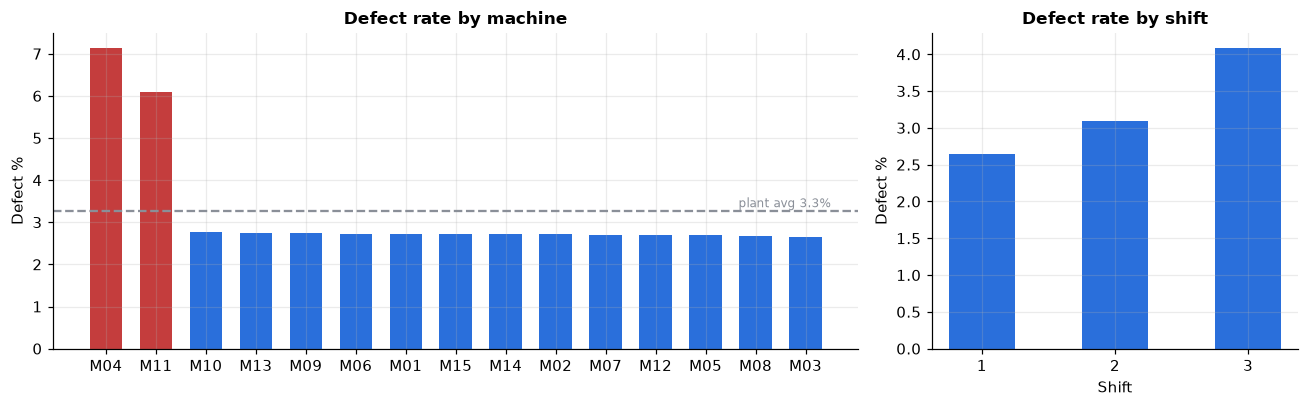

First Pass Yield 96.7% | scrapped parts 130,316 | scrap cost Rs 234.6 Lakh (180 d) -> Rs 3.91 Cr / yr
Top two machines (M04, M11) produce 28% of all scrap from 14% of volume


In [10]:
q = prod.groupby("machine").agg(total=("total", "sum"), good=("good", "sum"))
q["defect_pct"] = (1 - q.good/q.total) * 100
q = q.sort_values("defect_pct", ascending=False)
sh = prod.groupby("shift").apply(lambda d: (1 - d.good.sum()/d.total.sum())*100, include_groups=False)
fpy = prod.good.sum()/prod.total.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].bar(q.index, q.defect_pct, color=[RED if m in bad_machines else BLUE for m in q.index], width=.65)
ax[0].axhline(prod_avg := (1-fpy)*100, color=GREY, ls="--"); ax[0].text(len(q)-.5, prod_avg+.1, f"plant avg {prod_avg:.1f}%", ha="right", color=GREY, fontsize=8)
ax[0].set(title="Defect rate by machine", ylabel="Defect %")
ax[1].bar(sh.index.astype(str), sh.values, color=BLUE, width=.5); ax[1].set(title="Defect rate by shift", xlabel="Shift", ylabel="Defect %")
plt.tight_layout(); plt.show()

scrap_parts = (prod.total - prod.good).sum()
scrap_cost = scrap_parts * SCRAP_COST_PER_PART
print(f"First Pass Yield {fpy:.1%} | scrapped parts {scrap_parts:,} | scrap cost Rs {scrap_cost/1e5:,.1f} Lakh (180 d) -> Rs {scrap_cost*ANNUAL/1e7:,.2f} Cr / yr")
top2 = (q.total - q.good).head(2)
print(f"Top two machines ({', '.join(top2.index)}) produce {top2.sum()/scrap_parts:.0%} of all scrap from {q.total.head(2).sum()/q.total.sum():.0%} of volume")

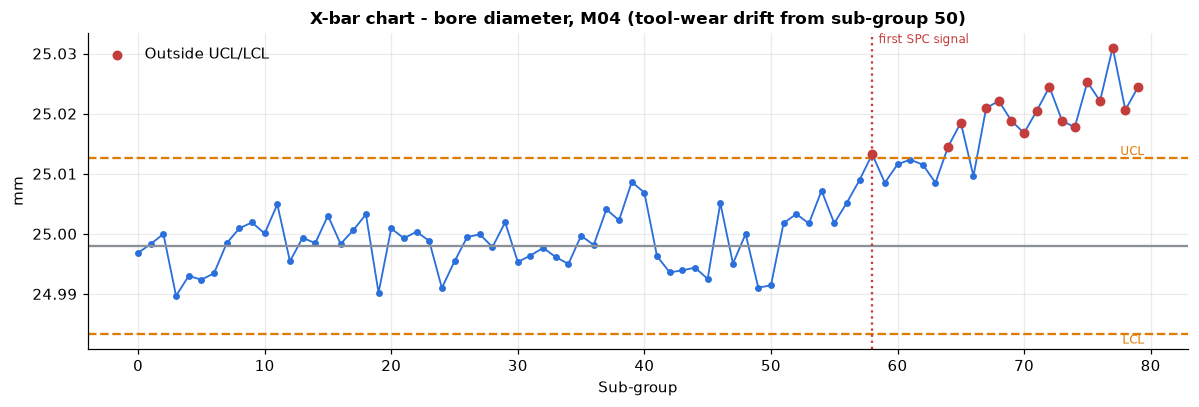

Drift began at sub-group 50. First SPC signal at sub-group 58 (8 groups later).
Sub-group means stay inside the +/-0.050 spec (yes) at the time of the signal - SPC flags the trend while parts are still conforming, so the tool can be changed before scrap is made.


In [11]:
# SPC: bore diameter on M04, 80 sub-groups of 5. Target 25.000 mm, tolerance +/-0.050.
rng = np.random.default_rng(7)
n_sg, n = 80, 5
mu = np.full(n_sg, 25.000)
mu[50:] += np.linspace(0, .028, n_sg-50)            # tool wear drift starts at sub-group 50
x = rng.normal(mu[:, None], .012, (n_sg, n))
xbar, R = x.mean(1), x.max(1) - x.min(1)
A2 = 0.577                                           # constant for n=5
cl, rbar = xbar[:25].mean(), R[:25].mean()           # limits from the first 25 in-control groups
ucl, lcl = cl + A2*rbar, cl - A2*rbar

beyond = np.where((xbar > ucl) | (xbar < lcl))[0]
side = np.sign(xbar - cl)                            # Western Electric: 8 in a row same side
run8 = [i for i in range(7, n_sg) if abs(side[i-7:i+1].sum()) == 8]
first_signal = min(list(beyond[:1]) + run8[:1])

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(xbar, color=BLUE, marker="o", ms=3.5, lw=1.2)
ax.scatter(beyond, xbar[beyond], color=RED, zorder=3, s=30, label="Outside UCL/LCL")
ax.axhline(cl, color=GREY); ax.axhline(ucl, color=ORANGE, ls="--"); ax.axhline(lcl, color=ORANGE, ls="--")
ax.text(n_sg-.5, ucl, "UCL", color=ORANGE, va="bottom", ha="right", fontsize=8)
ax.text(n_sg-.5, lcl, "LCL", color=ORANGE, va="top", ha="right", fontsize=8)
ax.axvline(first_signal, color=RED, ls=":"); ax.text(first_signal+.5, ax.get_ylim()[1], "first SPC signal", color=RED, va="top", fontsize=8)
ax.set(title="X-bar chart - bore diameter, M04 (tool-wear drift from sub-group 50)", xlabel="Sub-group", ylabel="mm")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

usl = 25.050
out_of_spec = np.where(xbar[:first_signal+1] > usl)[0]
print(f"Drift began at sub-group 50. First SPC signal at sub-group {first_signal} ({first_signal-50} groups later).")
print(f"Sub-group means stay inside the +/-0.050 spec ({'yes' if not len(out_of_spec) else 'no'}) at the time of the signal - "
      "SPC flags the trend while parts are still conforming, so the tool can be changed before scrap is made.")

## 5. Business Impact — *what is it worth in ₹?*

Baselines come from this notebook's own data, annualised to 300 working days.
* **Predictive maintenance** saving is *measured* from the test window above (breakdown hours avoided × ₹3 L/h), haircut by an assumed 50% action rate and the cost of false alarms.
* **Quality / SPC** saving uses a **conservative 20%** scrap reduction — the *lower bound* of the deck's 20–35% range. This one is an **assumption**, not something the data proves.

,Basis,Annual baseline cost (Rs Cr),Annual saving (Rs Cr)
Predictive maintenance,"Measured on test window, net of 50% action rate + false alarms",32.08,6.90
Quality / SPC,Assumption: 20% scrap cut (low end of deck range),3.91,0.78
TOTAL,,35.98,7.68


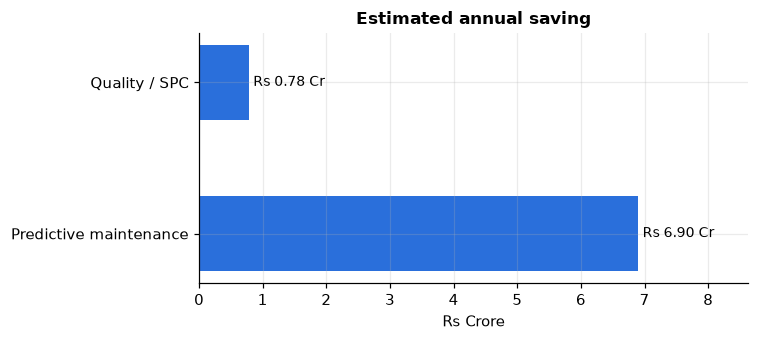

In [12]:
scrap_annual = scrap_cost * ANNUAL
bd_annual_cost = bd_hours * ANNUAL * COST_PER_DOWN_HR
qc_saving = 0.20 * scrap_annual

impact = pd.DataFrame({
    "Basis": ["Measured on test window, net of 50% action rate + false alarms", "Assumption: 20% scrap cut (low end of deck range)"],
    "Annual baseline cost (Rs Cr)": [bd_annual_cost/1e7, scrap_annual/1e7],
    "Annual saving (Rs Cr)": [pm_saving/1e7, qc_saving/1e7],
}, index=["Predictive maintenance", "Quality / SPC"])
impact.loc["TOTAL"] = ["", impact.iloc[:, 1].sum(), impact.iloc[:, 2].sum()]
display(impact.style.format({"Annual baseline cost (Rs Cr)": "{:,.2f}", "Annual saving (Rs Cr)": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [pm_saving/1e7, qc_saving/1e7]
ax.barh(["Predictive maintenance", "Quality / SPC"], vals, color=BLUE, height=.5)
for i, v in enumerate(vals): ax.text(v + max(vals)*.01, i, f"Rs {v:,.2f} Cr", va="center", fontsize=9)
ax.set(title="Estimated annual saving", xlabel="Rs Crore"); ax.set_xlim(0, max(vals)*1.25)
plt.tight_layout(); plt.show()

## 6. Takeaways and how we would run this for you

1. **Visibility first.** OEE decomposed by shift and machine, plus a downtime Pareto, turns "gut feel" into a ranked fix list — in the deck's 4–6 week MVP window.
2. **Breakdowns are rare but dominate cost.** Drift-based sensor features give planners days of notice instead of surprises.
3. **Scrap is concentrated.** A couple of machines and the night shift drive most of it; SPC flags tool-wear drift while parts are still in spec.
4. **Every number here is reproducible** (seeded) and each assumption is flagged. On real data we replace the simulation with your MES/SCADA/QC feeds and re-run the same pipeline.

**Next step:** a free 45-minute discovery session → data audit → MVP dashboard on *your* data (Week 3–6).

*Arihant Analytics · arihantdataanalytics@gmail.com · www.arihantanalytics.in  · +91 8888970671*